### Machine Learning | Assignment 2 - Supervised Learning

145873 | Sezer Tetik


In [363]:
import numpy as np
import matplotlib.pyplot as plt

seed = 30
np.random.seed(seed)

In [364]:
vectors = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

d = np.array([0, 0, 0, 1]) # AND 
d

array([0, 0, 0, 1])

In [365]:
w0 = np.random.rand(1)[0]
w1 = np.random.rand(1)[0]
w2 = np.random.rand(1)[0]

w0, w1, w2

(np.float64(0.644143536068335),
 np.float64(0.38074848963511654),
 np.float64(0.6630479053356686))

In [366]:
o = []
for (x1, x2) in vectors:
    o.append(1 if w0 + w1 * x1 + w2 * x2 > 0.5 else 0)
o

[1, 1, 1, 1]

In [367]:
e = d - o

e

array([-1, -1, -1,  0])

In [368]:
alpha = 10e-4

dw0 = dw1 = dw2 = 0

for (ep, (x1, x2)) in zip(e, vectors):
    dw0 += alpha * ep
    dw1 += alpha * x1 * ep
    dw2 += alpha * x2 * ep

w0 += dw0
w1 += dw1
w2 += dw2

w0, w1, w2

(np.float64(0.641143536068335),
 np.float64(0.37974848963511654),
 np.float64(0.6620479053356686))

In [369]:
def train(
        data,
        desired,
        weights,
        epoch = 10, 
        learning_rate = 10e-4):
    w0, w1, w2 = weights
    errors = []
    history = []
    converge_epoch = 0
    for i in range(epoch):
        dw0 = dw1 = dw2 = 0
        o = []
        for (x1, x2) in data:
            o.append(1 if w0 + w1 * x1 + w2 * x2 > 0.5 else 0)
        
        e = desired - o
        errors.append(np.sum(e ** 2))

        if np.all(e == 0):
            history.append([w0, w1, w2])
            converge_epoch = i + 1
            break

        for (ep, (x1, x2)) in zip(e, data):
            dw0 += learning_rate * ep
            dw1 += learning_rate * x1 * ep
            dw2 += learning_rate * x2 * ep

        w0 += dw0
        w1 += dw1
        w2 += dw2
        history.append([w0, w1, w2])

    return [w0, w1, w2], errors, np.array(history), converge_epoch if converge_epoch else -1

In [370]:
weights, errors, history, _ = train(vectors, d, [w0, w1, w2], 20)
weights

[np.float64(0.5811435360683349),
 np.float64(0.3597484896351165),
 np.float64(0.6420479053356686)]

In [371]:
def plot_error_per_epoch(errors):
    _, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, len(errors) + 1), errors, linewidth=2, color="#2a78d6")
    ax.set_title("Error per epoch")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Sum of squared errors")
    ax.grid(axis="y", color="#e5e5e5")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

def plot_weights_per_epoch(history):
    epochs = range(1, len(history) + 1)
    colors = ["#2a78d6", "#eb6834", "#1baf7a"]

    _, ax = plt.subplots(figsize=(8, 4))
    for i, color in enumerate(colors):
        ax.plot(epochs, history[:, i], linewidth=2, color=color, label=f"w{i}")
        ax.annotate(f"w{i}", (epochs[-1], history[-1, i]),
                    xytext=(6, 0), textcoords="offset points", va="center")
    ax.set_title("Weights per epoch")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weight value")
    ax.grid(axis="y", color="#e5e5e5")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    plt.show()

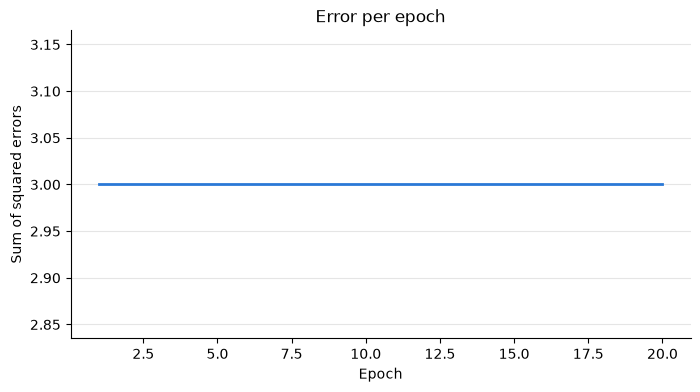

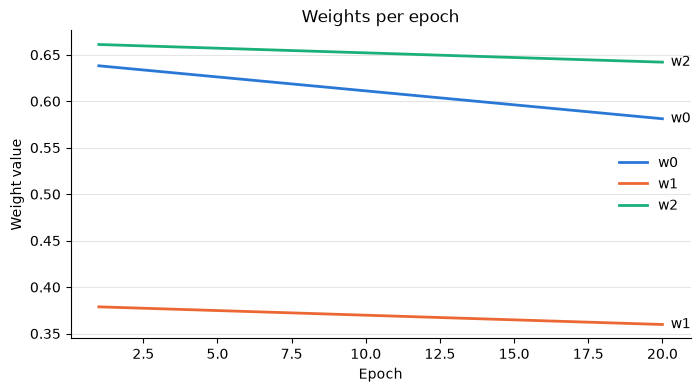

In [372]:
plot_error_per_epoch(errors)
plot_weights_per_epoch(history)

With the $epoch = 20$ and $\alpha = 0.001$, the model could not converge. The SSE was 3, did not improve after 20 epochs.

Also, in weights per epoch plot, it is possible to observe that the weights are moving very slowly, which is a sign of a small learning rate or epoch. The weights are not able to reach the optimal values in 20 epochs.

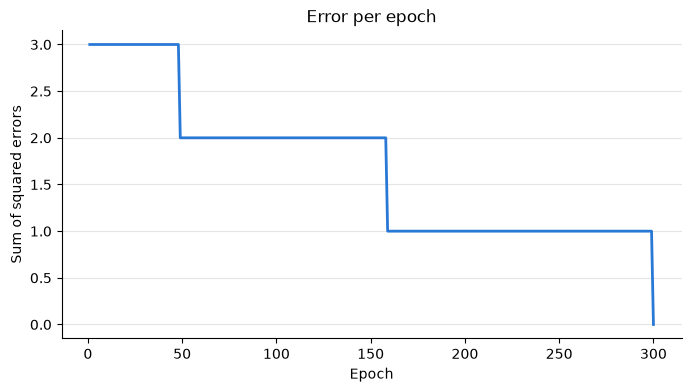

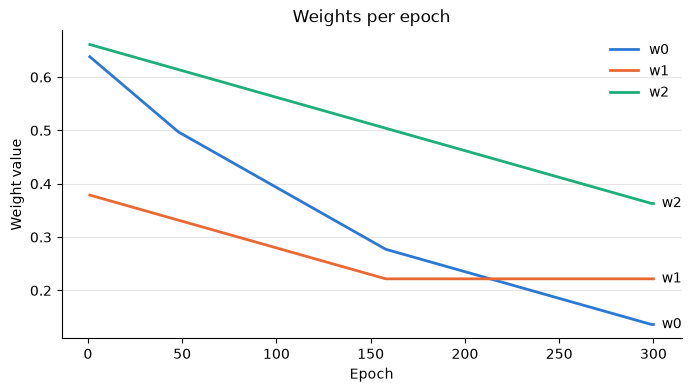

In [373]:
weights, errors, history, _ = train(vectors, d, [w0, w1, w2], 422)
weights

plot_error_per_epoch(errors)
plot_weights_per_epoch(history)

With the $epoch = 422$ and $\alpha = 0.001$, the model converged.

Also, since the learning rate is small, the weights are moving slowly and it took 422 epochs to reach the optimal values.

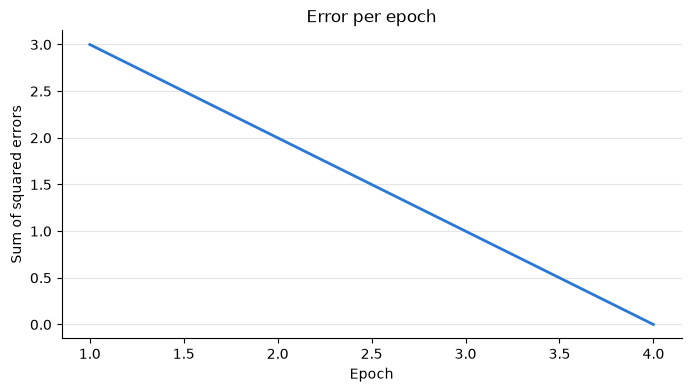

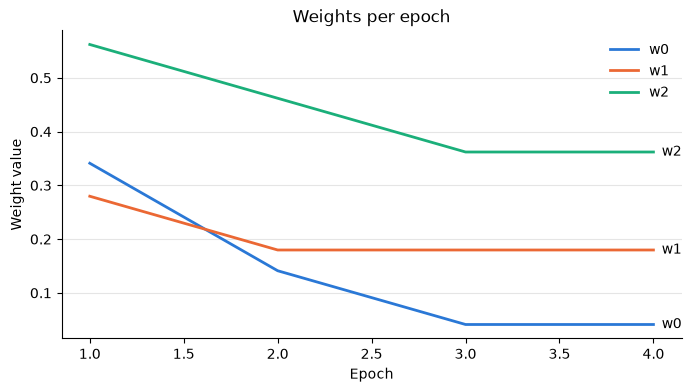

In [374]:
weights, errors, history, _ = train(vectors, d, [w0, w1, w2], 20, 10e-2)
weights

plot_error_per_epoch(errors)
plot_weights_per_epoch(history)

With the $epoch = 20$ and $\alpha = 0.1$, the model also converged.

Also, since the learning rate is larger, the weights are moving faster and fluctuate more and it took only 9 epochs to reach the optimal values.

In [375]:
def experiment(vectors, sample):
    np.random.seed(None)

    convergence_history = []
    errors_runs = []
    history_runs = []

    for i in range(sample):
        w0 = np.random.rand(1)[0]
        w1 = np.random.rand(1)[0]
        w2 = np.random.rand(1)[0]

        weights, errors, history, convergence = train(vectors, d, [w0, w1, w2], 500)
        convergence_history.append(convergence)
        errors_runs.append(errors)
        history_runs.append(history)
        
        print(f"sample {i + 1} | w0 = {w0}, w1 = {w1}, w2 = {w2}: converged in '{convergence}' epoch")

    print("To converge:")
    print("mean:", np.mean(convergence_history))
    print("sd:", np.std(convergence_history))

    return history_runs, errors_runs

def plot_experiment(history_runs, errors_runs, experiment_count):
    _, ax = plt.subplots(figsize=(8, 4))
    for errors in errors_runs:
        ax.plot(range(1, len(errors) + 1), errors, linewidth=1, color="#2a78d6", alpha=0.4)
    ax.set_title(f"Error per epoch ({experiment_count} runs)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Sum of squared errors")
    ax.grid(axis="y", color="#e5e5e5")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

    colors = ["#2a78d6", "#eb6834", "#1baf7a"]
    _, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for i, (ax, color) in enumerate(zip(axes, colors)):
        for history in history_runs:
            ax.plot(range(1, len(history) + 1), history[:, i], linewidth=1, color=color, alpha=0.4)
        ax.set_title(f"w{i} per epoch ({experiment_count} runs)")
        ax.set_xlabel("Epoch")
        ax.grid(axis="y", color="#e5e5e5")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Weight value")
    plt.show()


sample 1 | w0 = 0.36176972183545797, w1 = 0.8293888717721689, w2 = 0.09588235508949994: converged in '347' epoch
sample 2 | w0 = 0.11288637178647176, w1 = 0.5794096009606724, w2 = 0.9787321366590106: converged in '265' epoch
sample 3 | w0 = 0.5559016755143603, w1 = 0.3416465670573945, w2 = 0.900314089439509: converged in '407' epoch
sample 4 | w0 = 0.43719117413242425, w1 = 0.4947788225079256, w2 = 0.6979742562688954: converged in '247' epoch
sample 5 | w0 = 0.8577468468347044, w1 = 0.26597191705034184, w2 = 0.23867449813360808: converged in '174' epoch
sample 6 | w0 = 0.7046815095183021, w1 = 0.5838629094455345, w2 = 0.016166587764373408: converged in '373' epoch
sample 7 | w0 = 0.6415658622210867, w1 = 0.6981061247615807, w2 = 0.9269773114657234: converged in '380' epoch
sample 8 | w0 = 0.055139000609403355, w1 = 0.11011438593497513, w2 = 0.4722933246721205: converged in '15' epoch
sample 9 | w0 = 0.7240001468412128, w1 = 0.9545840361835423, w2 = 0.6262905732906203: converged in '424

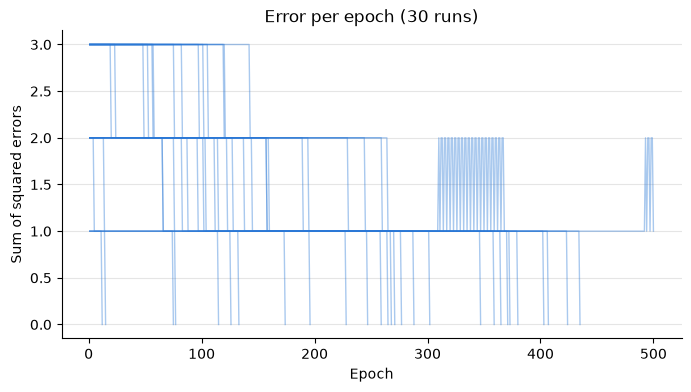

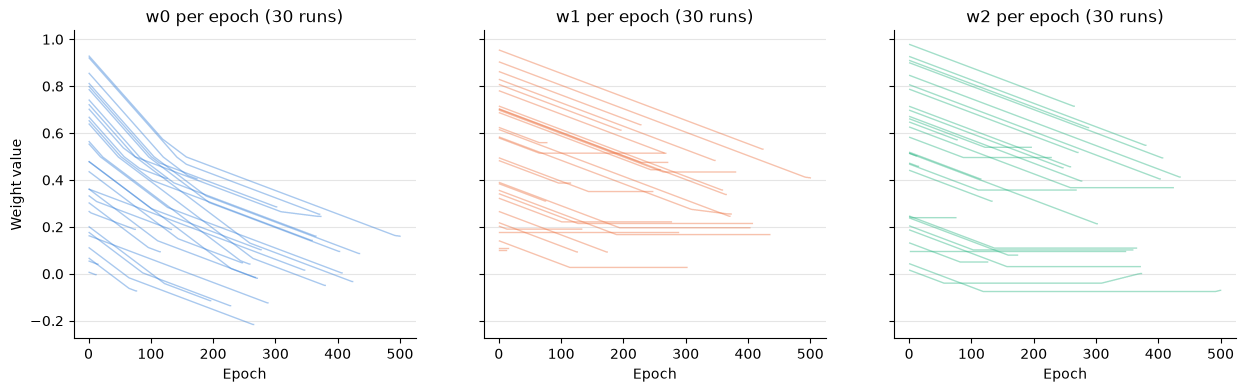

In [376]:
experiment_count = 30
history_runs, errors_runs = experiment(vectors, experiment_count)
plot_experiment(history_runs, errors_runs, experiment_count)

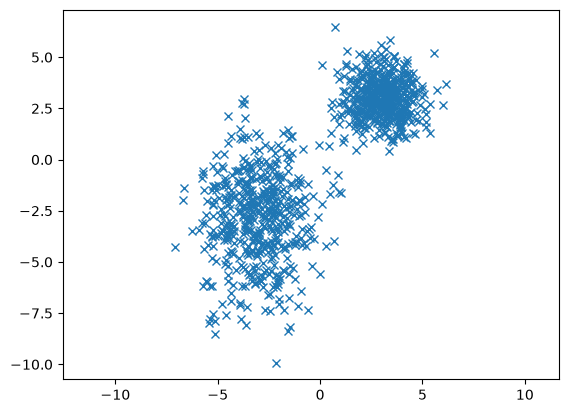

In [377]:
np.random.seed(seed)

mean1 = [3, 3]
cov1 = [[1, 0], [0, 1]]
points1 = np.random.multivariate_normal(mean1, cov1, 500) # so, in a row: [x, y]
points1 = np.concatenate((points1, np.ones((500, 1))), axis=1)

mean2 = [-3, -3]
cov2 = [[2, 0], [0, 5]]
points2 = np.random.multivariate_normal(mean2, cov2, 500)
points2 = np.concatenate((points2, np.array([[2]] * 500)), axis=1)

points_c = np.concatenate((points1, points2)) # axis 0 concatenate data vertically

np.random.shuffle(points_c)

x = points_c[:,0] # extract first column
y = points_c[:,1]

plt.plot(x, y, 'x')
plt.axis('equal')
plt.show()

np.savetxt("data.csv", points_c, delimiter=",", header="x,y,label")

In [378]:
split_id = int(len(points_c) * 0.7)
train_70, test_30 = points_c[:split_id], points_c[split_id:]

points_train, desired_train = train_70[:, :2], train_70[:, 2] - 1 # -1 to convert labels '1' and '2' to '0' and '1'

len(train_70), points_train.shape, desired_train.shape

(700, (700, 2), (700,))

[0.99564879 0.50937969 0.72566825]


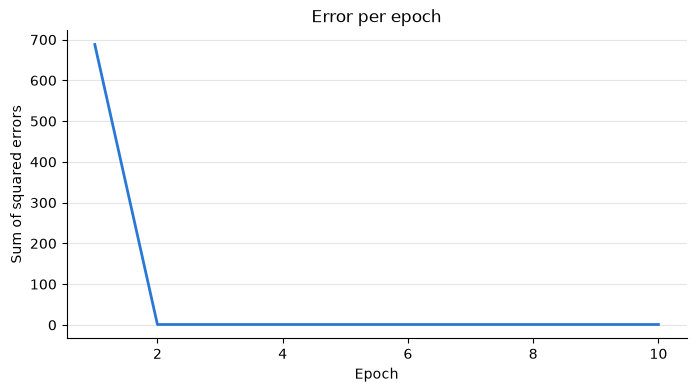

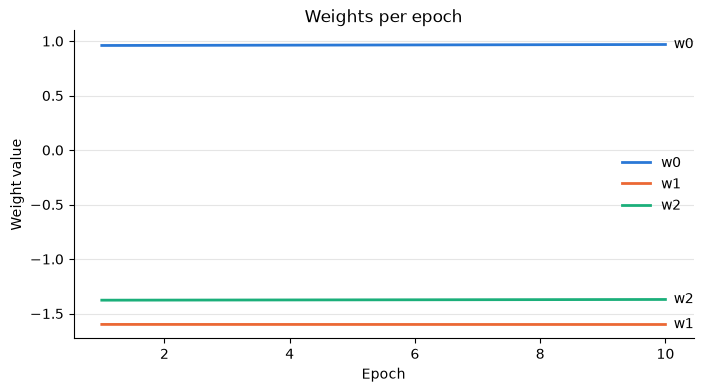

[np.float64(0.9686487946544642),
 np.float64(-1.6002276686196952),
 np.float64(-1.3706446367687843)]

In [379]:
initial_weights = np.random.rand(3)
print(initial_weights)

weights, errors, history, _ = train(points_train, desired_train, initial_weights)

plot_error_per_epoch(errors)
plot_weights_per_epoch(history)
weights

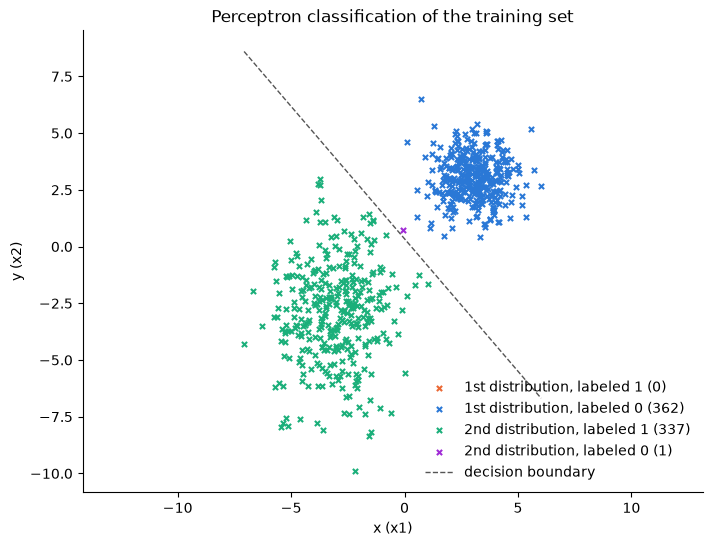

In [380]:
w0, w1, w2 = weights
o_train = np.array([1 if w0 + w1 * x1 + w2 * x2 > 0.5 else 0 for (x1, x2) in points_train])

groups = [
    (0, 1, "#eb6834", "1st distribution, labeled 1"),
    (0, 0, "#2a78d6", "1st distribution, labeled 0"),
    (1, 1, "#1baf7a", "2nd distribution, labeled 1"),
    (1, 0, "#a02bd6", "2nd distribution, labeled 0"),
]

_, ax = plt.subplots(figsize=(8, 6))
for dist, label, color, name in groups:
    mask = (desired_train == dist) & (o_train == label)
    ax.scatter(points_train[mask, 0], points_train[mask, 1], s=14, marker="x", color=color, label=f"{name} ({mask.sum()})")

# decision boundary: w0 + w1 * x + w2 * y = 0.5; x: x1 and y: x2
w0, w1, w2 = weights
xs = np.linspace(points_train[:, 0].min(), points_train[:, 0].max(), 100)
ax.plot(xs, (0.5 - w0 - w1 * xs) / w2, color="#555555", linestyle="--", linewidth=1, label="decision boundary")

ax.set_title("Perceptron classification of the training set")
ax.set_xlabel("x (x1)")
ax.set_ylabel("y (x2)")
ax.axis("equal")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

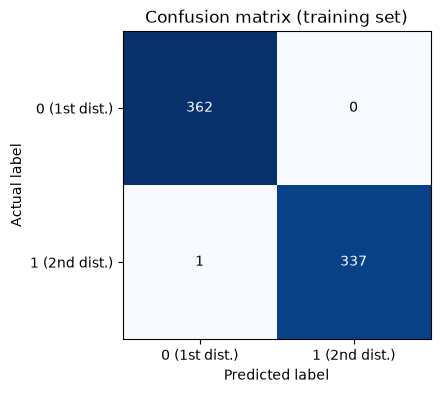

accuracy: 0.9986


array([[362,   0],
       [  1, 337]])

In [381]:
def plot_confusion_matrix(desired, output, title):
    matrix = np.zeros((2, 2), dtype=int)
    for (actual, predicted) in zip(desired.astype(int), output):
        matrix[actual, predicted] += 1

    _, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, matrix[i, j], ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")
    ax.set_xticks([0, 1], ["0 (1st dist.)", "1 (2nd dist.)"])
    ax.set_yticks([0, 1], ["0 (1st dist.)", "1 (2nd dist.)"])
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    plt.show()

    accuracy = np.trace(matrix) / matrix.sum()
    print(f"accuracy: {accuracy:.4f}")
    return matrix

plot_confusion_matrix(desired_train, o_train, "Confusion matrix (training set)")

In confusion matrix, we can relate the colors that we specified in the above layer as follows:
<br/><br/>
$TN: 362$ (Blue)
<br/>
$TP: 337$ (Green)
<br/>
$FP: 0$ (Orange)
<br/>
$FN: 1$ (Purple)

In [382]:
def experiment_v2(data, desired, sample, epoch = 1000, learning_rate = 10e-4):
    np.random.seed(None)

    convergence_history = []
    errors_runs = []
    history_runs = []

    for i in range(sample):
        w0, w1, w2 = np.random.rand(3)

        weights, errors, history, convergence = train(data, desired, [w0, w1, w2], epoch, learning_rate)
        convergence_history.append(convergence)
        errors_runs.append(errors)
        history_runs.append(history)

        print(f"sample {i + 1} | w0 = {w0}, w1 = {w1}, w2 = {w2}: converged in '{convergence}' epoch")

    converged = [c for c in convergence_history if c != -1] # -1 means not converged, exclude from stats
    print(f"converged: {len(converged)}/{sample}")
    if converged:
        print("To converge:")
        print("mean:", np.mean(converged))
        print("sd:", np.std(converged))

    return history_runs, errors_runs, np.array(convergence_history)

sample 1 | w0 = 0.6822411506632506, w1 = 0.8773454868382119, w2 = 0.6501646068281566: converged in '516' epoch
sample 2 | w0 = 0.8875914063884499, w1 = 0.911234382431895, w2 = 0.10251554887810188: converged in '528' epoch
sample 3 | w0 = 0.35310661014133937, w1 = 0.8273385761095414, w2 = 0.07805915826665599: converged in '788' epoch
sample 4 | w0 = 0.2328797108659939, w1 = 0.8628000451505374, w2 = 0.754482447589165: converged in '718' epoch
sample 5 | w0 = 0.47229083383621384, w1 = 0.534283568805352, w2 = 0.9374177280919516: converged in '516' epoch
sample 6 | w0 = 0.05173263938660844, w1 = 0.45059600289856994, w2 = 0.48861153761527765: converged in '960' epoch
sample 7 | w0 = 0.08650390106555228, w1 = 0.045251074034195815, w2 = 0.5815349666947691: converged in '932' epoch
sample 8 | w0 = 0.7962192053491937, w1 = 0.6571811042536424, w2 = 0.37396950869674195: converged in '561' epoch
sample 9 | w0 = 0.27932625593641636, w1 = 0.7099513187839679, w2 = 0.465321941220752: converged in '789'

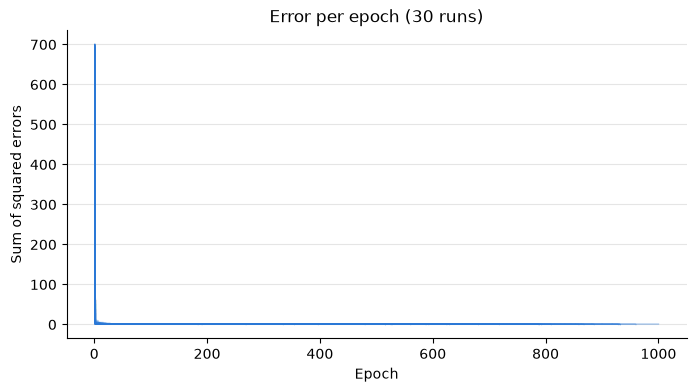

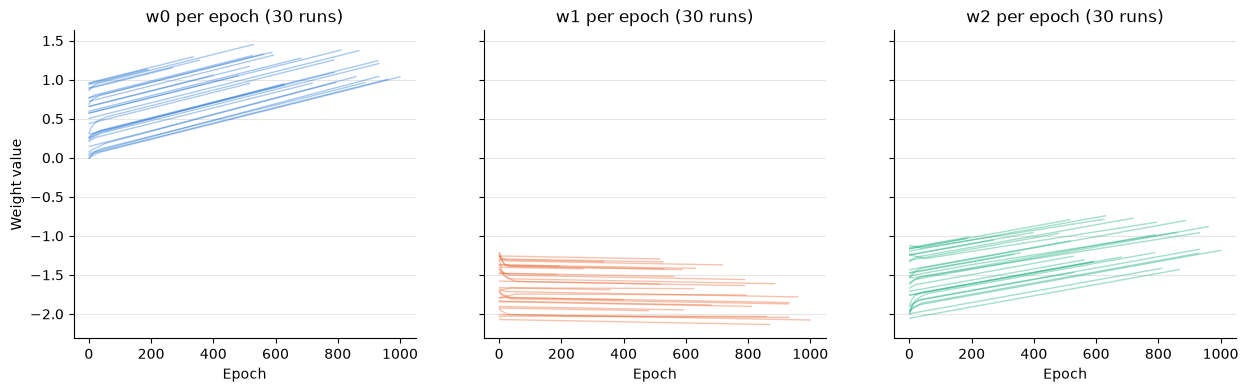

In [383]:
experiment_count = 30
history_runs, errors_runs, convergence_history = experiment_v2(points_train, desired_train, experiment_count)
plot_experiment(history_runs, errors_runs, experiment_count)

In [384]:
points_test, desired_test = test_30[:, :2], test_30[:, 2] - 1

len(test_30), points_test.shape, desired_test.shape

(300, (300, 2), (300,))

In [385]:
def predict(weights, data):
    w0, w1, w2 = weights
    return np.array([1 if w0 + w1 * x1 + w2 * x2 > 0.5 else 0 for (x1, x2) in data])

def confusion_matrix(desired, output):
    # rows: actual, columns: predicted -> 
    # [
    #   [TN, FP], 
    #   [FN, TP]
    # ]
    matrix = np.zeros((2, 2), dtype=int)
    for (actual, predicted) in zip(desired.astype(int), output):
        matrix[actual, predicted] += 1
    return matrix

def metrics(matrix):
    (tn, fp), (fn, tp) = matrix
    accuracy = (tp + tn) / matrix.sum()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)
    return accuracy, precision, recall, f1

In [386]:
final_weights = [history[-1] for history in history_runs]

matrices = []
metrics_runs = []
for i, weights in enumerate(final_weights):
    matrix = confusion_matrix(desired_test, predict(weights, points_test))
    matrices.append(matrix)
    metrics_runs.append(metrics(matrix))

    (tn, fp), (fn, tp) = matrix
    accuracy, precision, recall, f1 = metrics_runs[-1]
    print(f"test {i + 1} | TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp} | accuracy = {accuracy:.4f}, precision = {precision:.4f}, recall = {recall:.4f}, f1 = {f1:.4f}")

matrices = np.array(matrices)
metrics_runs = np.array(metrics_runs)

print(f"\nAverage over {len(final_weights)} tests:")
for name, mean, sd in zip(["accuracy", "precision", "recall", "f1"], metrics_runs.mean(axis=0), metrics_runs.std(axis=0)):
    print(f"{name}: {mean:.4f} (sd: {sd:.4f})")

test 1 | TN = 138, FP = 0, FN = 1, TP = 161 | accuracy = 0.9967, precision = 1.0000, recall = 0.9938, f1 = 0.9969
test 2 | TN = 138, FP = 0, FN = 1, TP = 161 | accuracy = 0.9967, precision = 1.0000, recall = 0.9938, f1 = 0.9969
test 3 | TN = 138, FP = 0, FN = 1, TP = 161 | accuracy = 0.9967, precision = 1.0000, recall = 0.9938, f1 = 0.9969
test 4 | TN = 138, FP = 0, FN = 2, TP = 160 | accuracy = 0.9933, precision = 1.0000, recall = 0.9877, f1 = 0.9938
test 5 | TN = 138, FP = 0, FN = 2, TP = 160 | accuracy = 0.9933, precision = 1.0000, recall = 0.9877, f1 = 0.9938
test 6 | TN = 138, FP = 0, FN = 2, TP = 160 | accuracy = 0.9933, precision = 1.0000, recall = 0.9877, f1 = 0.9938
test 7 | TN = 138, FP = 0, FN = 2, TP = 160 | accuracy = 0.9933, precision = 1.0000, recall = 0.9877, f1 = 0.9938
test 8 | TN = 138, FP = 0, FN = 1, TP = 161 | accuracy = 0.9967, precision = 1.0000, recall = 0.9938, f1 = 0.9969
test 9 | TN = 138, FP = 0, FN = 2, TP = 160 | accuracy = 0.9933, precision = 1.0000, rec

In [387]:
from sklearn.metrics import confusion_matrix as sk_confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

for i, weights in enumerate(final_weights):
    output = predict(weights, points_test)
    expected = [
        accuracy_score(desired_test, output),
        precision_score(desired_test, output, zero_division=0),
        recall_score(desired_test, output, zero_division=0),
        f1_score(desired_test, output, zero_division=0),
    ]
    assert np.array_equal(matrices[i], sk_confusion_matrix(desired_test, output, labels=[0, 1])), f"test {i + 1}: confusion matrix mismatch"
    assert np.allclose(metrics_runs[i], expected), f"test {i + 1}: metrics mismatch"